# Example 6.3: Statistical Variability of the GA in 5 Runs

**Chapter 6 — Trajectory Synthesis with Genetic Algorithms**

Analyze the variability of the GA executed 5 times with different seeds.

In [1]:
from numpy import *
import matplotlib.pyplot as plt

def fourbar_coupler(a, b, c, d, th2, p=35.0, delta=pi/5):
    K1 = d / a
    K2 = d / c
    K3 = (a**2 - b**2 + c**2 + d**2) / (2 * a * c)

    A = cos(th2) - K1 - K2 * cos(th2) + K3
    B = -2 * sin(th2)
    C = K1 - (K2 + 1) * cos(th2) + K3

    disc = B**2 - 4 * A * C
    th4 = where(disc >= 0, 2 * arctan2(-B - sqrt(maximum(disc, 0)), 2 * A), nan)

    K4 = d / b
    K5 = (c**2 - d**2 - a**2 - b**2) / (2 * a * b)

    A2 = cos(th2) - K1 + K4 * cos(th2) + K5
    B2 = -2 * sin(th2)
    C2 = K1 + (K4 - 1) * cos(th2) + K5

    disc2 = B2**2 - 4 * A2 * C2
    th3 = where(disc >= 0, 2 * arctan2(-B2 - sqrt(maximum(disc2, 0)), 2 * A2), nan)

    return a * cos(th2) + p * cos(th3 + delta), a * sin(th2) + p * sin(th3 + delta)

def hausdorff(Cx, Cy, Px, Py):
    m = isfinite(Cx)
    if not m.any():
        return 1e6
    D = sqrt((Cx[m, None] - Px)**2 + (Cy[m, None] - Py)**2)
    # We use builtins.max explicitly to avoid conflicts with numpy.max in numpy 2.x/3.x
    import builtins
    return builtins.max(float(D.min(0).max()), float(D.min(1).max()))

t = linspace(0, 2 * pi, 20)
Px = 45 + 22 * cos(t)
Py = 25 + 18 * sin(t)
th2v = linspace(0, 2 * pi, 72)

def ga_run(seed):
    r = random.default_rng(seed)
    pop = r.uniform(10, 120, (15, 3))
    h = []
    for _ in range(25):
        fit = array([hausdorff(*fourbar_coupler(p[0], p[1], p[2], 85.0, th2v), Px, Py) for p in pop])
        h.append(fit.min())
        idx = argsort(fit)[:8]
        elite = pop[idx]
        hijos = []
        for __ in range(15 - 8):
            i1, i2 = r.choice(8, 2, replace=False)
            pt = r.integers(1, 3)
            hi = concatenate([elite[i1, :pt], elite[i2, pt:]])
            mask = r.random(3) < 0.12
            hi[mask] += r.normal(0, 5, mask.sum())
            hijos.append(clip(hi, 10, 120))
        pop = vstack([elite, hijos])
    return array(h)

historials = array([ga_run(s) for s in range(5)])
errores_finales = historials[:, -1]

print('Results of 5 independent runs:')
for i, (e, hist) in enumerate(zip(errores_finales, historials)):
    print(f'  Run {i+1}: {hist[0]:.2f} → {e:.2f} mm')

print(f'\nMedian final error: {median(errores_finales):.2f} mm')
print(f'10th Percentile:    {percentile(errores_finales, 10):.2f} mm')
print(f'90th Percentile:    {percentile(errores_finales, 90):.2f} mm')
print(f'Best run: {argmin(errores_finales)+1} ({errores_finales.min():.2f} mm)')
print(f'Worst run: {argmax(errores_finales)+1} ({errores_finales.max():.2f} mm)')

Results of 5 independent runs:
  Run 1: 31.28 → 14.21 mm
  Run 2: 45.51 → 29.08 mm
  Run 3: 24.17 → 14.17 mm
  Run 4: 52.35 → 20.60 mm
  Run 5: 36.37 → 17.64 mm

Median final error: 17.64 mm
10th Percentile:    14.19 mm
90th Percentile:    25.69 mm
Best run: 3 (14.17 mm)
Worst run: 2 (29.08 mm)


## Display — P10–P90 and median band

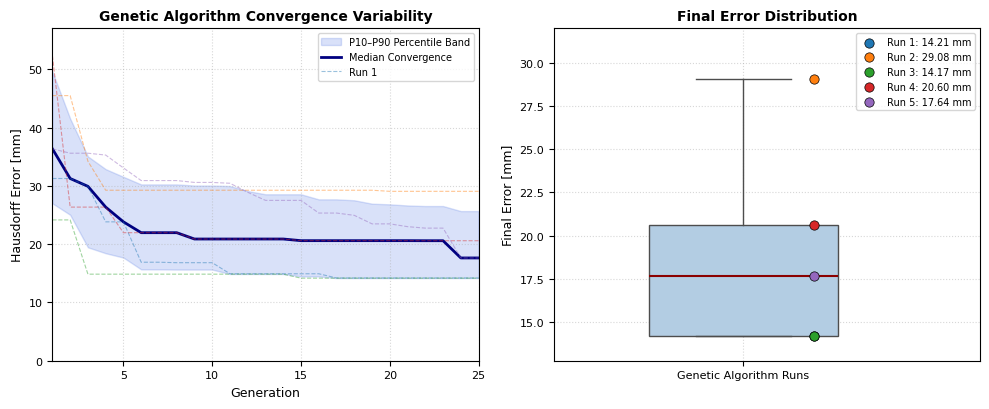

In [3]:
import os
import glob

# Dynamic naming system according to the guidelines
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "Figure_6_3_ga_statistical_variability"
except Exception:
    notebook_name = "Figure_6_3_ga_statistical_variability"

# Configure Springer editorial standards (Sans-Serif, editable vector fonts)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']

# Balanced figure size for publication
fig, axes = plt.subplots(1, 2, figsize=(10.0, 4.2))

# --- Left Subplot: Convergence Bands ---
p10 = percentile(historials, 10, axis=0)
p90 = percentile(historials, 90, axis=0)
med = median(historials, axis=0)
gens = arange(1, 26)

axes[0].fill_between(gens, p10, p90, alpha=0.2, color='royalblue', label='P10–P90 Percentile Band')
axes[0].plot(gens, med, color='navy', lw=2.0, label='Median Convergence')

# Plot individual run histories with elegant styling
for i, h in enumerate(historials):
    axes[0].plot(gens, h, alpha=0.45, lw=0.8, ls='--', label=f'Run {i+1}' if i == 0 else "")

axes[0].set_xlabel('Generation', fontsize=9)
axes[0].set_ylabel('Hausdorff Error [mm]', fontsize=9)
axes[0].set_title('Genetic Algorithm Convergence Variability', fontsize=10, fontweight='semibold')
axes[0].set_xlim(1, 25)
# Provide safety top margin for legend and annotations
axes[0].set_ylim(0, max(p90) * 1.15)
axes[0].legend(fontsize=7, loc='upper right')
axes[0].grid(True, linestyle=':', alpha=0.5)
axes[0].tick_params(labelsize=8)

# --- Right Subplot: Final Errors Boxplot ---
box = axes[1].boxplot(
    errores_finales,
    vert=True,
    patch_artist=True,
    widths=0.4,
    boxprops=dict(facecolor='#b3cde3', color='#4d4d4d', lw=1),
    capprops=dict(color='#4d4d4d', lw=1),
    whiskerprops=dict(color='#4d4d4d', lw=1),
    flierprops=dict(marker='o', markerfacecolor='red', markersize=5),
    medianprops=dict(color='darkred', lw=1.5)
)

# Overlay scatter of actual run values with a clean legend mapping
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
for i, e in enumerate(errores_finales):
    axes[1].scatter(1.15, e, zorder=5, s=45, color=colors[i], edgecolors='k', lw=0.5, label=f'Run {i+1}: {e:.2f} mm')

axes[1].set_xlim(0.6, 1.5)
axes[1].set_xticks([1])
axes[1].set_xticklabels(['Genetic Algorithm Runs'], fontsize=8)
axes[1].set_ylabel('Final Error [mm]', fontsize=9)
axes[1].set_title('Final Error Distribution', fontsize=10, fontweight='semibold')
# Provide safety margin
axes[1].set_ylim(min(errores_finales) * 0.9, max(errores_finales) * 1.1)
axes[1].legend(fontsize=7, loc='upper right')
axes[1].grid(True, linestyle=':', alpha=0.5)
axes[1].tick_params(labelsize=8)

plt.tight_layout()

# Export figures per Springer instructions
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()